# 11 — Separate anomaly detection for the selected deployment

Run after 10. The candidate selected by the declared fold rule and its validation-selected cutoff are pinned once in `11_deployment/deployment_selection.json`. Later comparison runs cannot silently change that pin. This notebook does not refit the classifier or choose a new cutoff.

Isolation Forest remains a separate 2025 training-reference model, independent of the classifier's extra 2024 history. Reuse a compatible legacy detector when the training-file hash, formulas, parameters and package versions match; otherwise fit a new detector on training features only. Never fit on validation/test/latest observations or treat flags as confirmed errors.

New detector caches are separate under `11_anomalies/`. Scores cover train, validation and the prepared latest snapshot; test rows/labels are not loaded here. Existing detector and dashboard files remain intact. Run 12 next to explain and publish the selected classifier.

## 1. Verify the pinned candidate and anomaly training reference

The classifier is selected/frozen by 10/11. Only original 2025 training features fit the detector. No surge labels or future prices enter anomaly features.

In [1]:
import hashlib
import json
from importlib import metadata, reload
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
import pricecatcher_config as cfg
cfg = reload(cfg)
pin, STUDY_DIR, study = cfg.dashboard_candidate()
selection = study["selection"]
PREPARED_DIR = cfg.PROJECT_ROOT / "experiments" / "holdout" / "05_modelling"
settings = json.loads((PREPARED_DIR / "experiment_settings.json").read_text())
train_sha256 = study["input_sha256"]["experiments/holdout/05_modelling/train.parquet"]
print("Pinned forecasting candidate:", pin["candidate"])
print("Frozen classifier cutoff:", selection["score_cutoff"])
print("Separate anomaly reference: original 2025 training features")

Pinned forecasting candidate: Longer-history LightGBM (tuned)
Frozen classifier cutoff: 0.22099133987116373
Separate anomaly reference: original 2025 training features


## Small reusable calculations
The same feature calculation is used for every period. Percentage features reduce the effect of different price units; they do not guarantee equal behaviour across food groups. Trees do not require feature scaling. Missing historical values are imputed using **training medians only**, with missingness indicators. No interpolation or future-price filling is used.

In [2]:
def file_hash(path):
    with Path(path).open("rb") as handle:
        return hashlib.file_digest(handle, "sha256").hexdigest()


RAW_FEATURES = ["weekly_median_price", "lag_1w_price", "lag_2w_price", "lag_4w_price",
                "weekly_price_change_pct", "rolling_mean_4w", "rolling_std_4w", "weekly_std_price"]
IDENTIFIERS = cfg.GROUP_KEYS + ["week_start", "next_week_end"]
FEATURE_FORMULAS = {
    "current_change_pct": "weekly_price_change_pct",
    "change_2w_pct": "100 * (weekly_median_price / lag_2w_price - 1)",
    "change_4w_pct": "100 * (weekly_median_price / lag_4w_price - 1)",
    "deviation_4w_pct": "100 * (weekly_median_price / rolling_mean_4w - 1)",
    "within_week_variation_pct": "100 * weekly_std_price / weekly_median_price",
    "history_variation_4w_pct": "100 * rolling_std_4w / rolling_mean_4w",
}


def anomaly_inputs(frame):
    """Current/past price patterns only; never use labels, future coverage or geography."""
    raw = frame[RAW_FEATURES].astype(float)
    prices = raw[["weekly_median_price", "lag_1w_price", "lag_2w_price", "lag_4w_price", "rolling_mean_4w"]]
    if (prices.le(0) & prices.notna()).any().any() or np.isinf(raw.to_numpy()).any():
        raise ValueError("Invalid price-history inputs. Restore the matching prepared snapshot.")
    price = raw.weekly_median_price
    inputs = pd.DataFrame({
        "current_change_pct": raw.weekly_price_change_pct,
        "change_2w_pct": 100 * (price / raw.lag_2w_price - 1),
        "change_4w_pct": 100 * (price / raw.lag_4w_price - 1),
        "deviation_4w_pct": 100 * (price / raw.rolling_mean_4w - 1),
        "within_week_variation_pct": 100 * raw.weekly_std_price / price,
        "history_variation_4w_pct": 100 * raw.rolling_std_4w / raw.rolling_mean_4w,
    }, index=frame.index)
    if np.isinf(inputs.to_numpy()).any():
        raise ValueError("Percentage features overflowed. Inspect the prepared price inputs.")
    return inputs


def load_period(name, settings):
    filename = "latest_prediction_inputs.parquet" if name == "latest" else f"{name}.parquet"
    frame = pd.read_parquet(PREPARED_DIR / filename, columns=IDENTIFIERS + RAW_FEATURES)
    for column in ["week_start", "next_week_end"]:
        frame[column] = pd.to_datetime(frame[column])
    if frame[IDENTIFIERS].isna().any().any() or frame.duplicated(cfg.GROUP_KEYS + ["week_start"]).any():
        raise ValueError(f"{name}: missing identifiers or duplicate series-weeks.")
    if not frame.week_start.dt.dayofweek.eq(0).all() or not frame.next_week_end.eq(frame.week_start + pd.Timedelta(days=13)).all():
        raise ValueError(f"{name}: incorrect calendar weeks or next-week horizon.")
    if name != "latest":
        upper = pd.Timestamp(settings[{"train": "train_end", "validation": "validation_end", "test": "test_end"}[name]])
        if frame.empty or not frame.next_week_end.le(upper).all():
            raise ValueError(f"{name}: empty rows or outcomes crossing the saved cutoff.")
        if name != "train":
            lower = pd.Timestamp(settings["train_end" if name == "validation" else "validation_end"])
            if not (frame.week_start + pd.Timedelta(days=6)).gt(lower).all():
                raise ValueError(f"{name}: prediction dates overlap the earlier split.")
    else:
        end = pd.Timestamp(settings["evaluation_end"])
        expected_week = end - pd.Timedelta(days=(end.dayofweek + 1) % 7 + 6)
        if not frame.week_start.eq(expected_week).all():
            raise ValueError("Latest rows are stale; restore the last complete-week inputs from 05.")
    return frame


def score_period(pipeline, frame, name):
    inputs = anomaly_inputs(frame)
    result = frame.copy()
    result[list(FEATURE_FORMULAS)] = inputs
    result["split"] = name
    if len(frame):
        # score_samples is lower for unusual rows; reverse it for readable ranking.
        result["anomaly_score"] = -pipeline.score_samples(inputs)
        result["is_anomaly"] = pipeline.predict(inputs) == -1
    else:
        result["anomaly_score"] = pd.Series(dtype=float)
        result["is_anomaly"] = pd.Series(dtype=bool)
    return result


In [3]:
for package in ["scikit-learn", "numpy", "pandas", "joblib"]:
    if metadata.version(package) != study["package_versions"][package]:
        raise ValueError(f"Use the selected study's {package} version before inference.")
if file_hash(PREPARED_DIR / "train.parquet") != train_sha256:
    raise ValueError("Prepared training inputs changed. Restore the selected study's snapshot.")
print("Verified original training inputs; no classifier fitting or test evaluation.")

Verified original training inputs; no classifier fitting or test evaluation.


## 2. Declare the detector before scoring later periods
Use one modest, fixed setting: **150 trees, up to 256 training rows per tree, seed 42, and contamination 0.01**. The 1% setting is a training review-budget heuristic, not the true proportion of errors or surges. Ties can yield fewer than 1% training flags; later periods can have different flag rates.

The decision threshold comes from training scores. There is no validation/test optimisation, surge-label matching, class weighting or SMOTE. Scores are not probabilities. All summaries below describe the model-ready population retained by 05, which can exclude sparse places; they do not cover every source record.

In [4]:
PARAMETERS = {"n_estimators": 150, "max_samples": 256, "contamination": 0.01,
              "random_state": 42, "n_jobs": 2}
protocol = {"schema_version": 1, "feature_formulas": FEATURE_FORMULAS, "parameters": PARAMETERS,
            "preprocessing": "training median imputation with missing indicators; keep empty columns",
            "training_end": settings["train_end"], "population": "supported modelling rows from 05"}
train = load_period("train", settings)
X_train = anomaly_inputs(train)
if len(train) < 2 or X_train.isna().all().any():
    raise ValueError("Too little observed training support for the anomaly features. Inspect 05; do not use later rows to fill training.")
print("Training rows:", len(train), "| Anomaly features:", len(X_train.columns))
display(X_train.describe().T)

identity = {"training_sha256": train_sha256, "protocol": protocol, "package_versions": {p:metadata.version(p) for p in ["scikit-learn", "numpy", "pandas", "joblib"]}}
OUTPUT_DIR = cfg.PROJECT_ROOT / "11_anomalies" / hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()[:16]
print("Anomaly cache:", OUTPUT_DIR)

Training rows: 195664 | Anomaly features: 6


,count,mean,std,min,25%,50%,75%,max
current_change_pct,195664.0,0.845277,12.288209,-86.914286,0.000000,0.000000,0.000000,503.691275
change_2w_pct,186626.0,1.613688,16.629370,-86.914286,-0.828640,0.000000,2.564103,353.846154
change_4w_pct,176970.0,2.083348,20.319760,-86.914286,-3.229279,0.000000,4.878049,454.444444
deviation_4w_pct,195664.0,0.895361,13.719088,-80.327869,-2.329999,0.000000,3.184713,338.596491
within_week_variation_pct,195664.0,8.925121,83.459625,0.000000,0.000000,4.456610,12.909944,34562.985567
history_variation_4w_pct,195664.0,5.649020,7.754646,0.000000,0.000000,2.659312,8.695652,120.309618


Anomaly cache: /Users/alfredyap/Documents/GitHub/FYP/data/runs/run_20261019_013241_618240/11_anomalies/2fae5011a2a6495c


## 3. Fit or reuse the separate detector

New caches live under `11_anomalies/`, keyed by training inputs, formulas, parameters and package version. Compatible legacy detectors are copied into a separate cache without fitting. A partial or changed cache stops instead of silently retraining.

In [5]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
model_path = OUTPUT_DIR / "isolation_forest.joblib"
manifest_path = OUTPUT_DIR / "anomaly_manifest.json"
if model_path.exists() or manifest_path.exists():
    if not model_path.is_file() or not manifest_path.is_file():
        raise FileNotFoundError("Partial anomaly cache. Restore its matching model and manifest.")
    anomaly_manifest = json.loads(manifest_path.read_text())
    if (anomaly_manifest["protocol"] != protocol or anomaly_manifest["training_input_sha256"] != train_sha256
            or anomaly_manifest["package_versions"]["scikit-learn"] != metadata.version("scikit-learn")
            or file_hash(model_path) != anomaly_manifest["model_sha256"]):
        raise ValueError("Anomaly cache differs from the frozen training reference.")
    detector = joblib.load(model_path)
    print("Reusing verified anomaly detector.")
else:
    legacy = cfg.PROJECT_ROOT / "07_anomalies"
    legacy_record = json.loads((legacy / "anomaly_manifest.json").read_text()) if (legacy / "anomaly_manifest.json").is_file() else {}
    compatible = (legacy_record.get("frozen_inputs", {}).get("holdout/train.parquet") == train_sha256
        and legacy_record.get("protocol", {}).get("feature_formulas") == FEATURE_FORMULAS
        and legacy_record.get("protocol", {}).get("parameters") == PARAMETERS
        and all(legacy_record.get("package_versions", {}).get(p) == metadata.version(p)
                for p in ["scikit-learn", "numpy", "pandas", "joblib"]))
    temporary_model = model_path.with_suffix(".joblib.tmp")
    if compatible:
        if file_hash(legacy / "isolation_forest.joblib") != legacy_record["model_sha256"]:
            raise ValueError("Compatible legacy detector was changed. Restore it; do not bypass hashes.")
        temporary_model.write_bytes((legacy / "isolation_forest.joblib").read_bytes())
        detector = joblib.load(temporary_model)
        reused_from = "07_anomalies/isolation_forest.joblib"
        print("Reusing the compatible original detector; no fitting.")
    else:
        detector = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
                             ("detector", IsolationForest(**PARAMETERS))])
        detector.fit(X_train)
        joblib.dump(detector, temporary_model)
        reused_from = None
        print("Fitted separate detector on 2025 training features only.")
    anomaly_manifest = {"protocol": protocol, "training_input_sha256": train_sha256,
        "training_rows": len(train), "reused_from": reused_from,
        "classifier_used_for_fit": False, "study_status": "unsupervised review signal; no anomaly ground truth",
        "training_score_threshold": float(-detector.named_steps["detector"].offset_),
        "model_sha256": file_hash(temporary_model),
        "package_versions": {p:metadata.version(p) for p in ["scikit-learn", "numpy", "pandas", "joblib"]}}
    temporary_manifest = manifest_path.with_suffix(".tmp")
    temporary_manifest.write_text(json.dumps(anomaly_manifest, indent=2))
    temporary_model.replace(model_path)
    temporary_manifest.replace(manifest_path)
print("Frozen anomaly threshold:", anomaly_manifest["training_score_threshold"])

Reusing the compatible original detector; no fitting.
Frozen anomaly threshold: 0.6537139786839229


## 4. Score train, validation and latest observations

All periods use the same training-fitted pipeline and threshold. Test rows and labels are not loaded. The latest period needs current/history support only; missing forecasts are not replaced by older local weeks.

In [6]:
scored_periods = []
for name in ["train", "validation", "latest"]:
    frame = train if name == "train" else load_period(name, settings)
    scored = score_period(detector, frame, name)
    scored_periods.append(scored)
    print(f"{name}: {len(scored):,} supported rows; {int(scored.is_anomaly.sum()):,} flagged")
anomaly_scores = pd.concat(scored_periods, ignore_index=True)
threshold = anomaly_manifest["training_score_threshold"]
assert np.array_equal(anomaly_scores.is_anomaly, anomaly_scores.anomaly_score.gt(threshold))
if not np.isfinite(anomaly_scores.anomaly_score.to_numpy(dtype=float)).all():
    raise ValueError("Non-finite anomaly scores; no scores published.")
anomaly_scores.to_parquet(OUTPUT_DIR / "anomaly_scores.parquet", index=False)
# Publish the exact detector/scores link after scoring succeeds.
link_path = cfg.PROJECT_ROOT / "11_deployment" / "anomaly_selection.json"
link = {"deployment_id": pin["deployment_id"], "manifest_path": str(manifest_path.relative_to(cfg.PROJECT_ROOT)),
        "manifest_sha256": file_hash(manifest_path), "scores_sha256": file_hash(OUTPUT_DIR / "anomaly_scores.parquet"),
        "training_input_sha256": train_sha256}
temporary = link_path.with_suffix(".tmp")
temporary.write_text(json.dumps(link, indent=2))
temporary.replace(link_path)


train: 195,664 supported rows; 1,957 flagged
validation: 43,594 supported rows; 639 flagged
latest: 5,343 supported rows; 45 flagged


PosixPath('/Users/alfredyap/Documents/GitHub/FYP/data/runs/run_20261019_013241_618240/11_deployment/anomaly_selection.json')

## 5. Inspect representation and review candidates
Compare flag rates alongside support counts. A higher group/state/district rate may reflect volatility, missingness or distribution change; it is not evidence that an area has more confirmed errors or deserves fewer services. Flags are not a correction policy. Do not delete prices or feed flags back into the supervised target labels.

The top 20 flagged rows per period are a review shortlist, not an unbiased sample for estimating anomaly accuracy. Record independent evidence if you later establish an error. Numerical feature values help describe a case but are not causal explanations or SHAP values.

,split,breakdown,group,rows,flagged,flag_rate_pct,project_group,state,district
0,train,overall,ALL,195664,1957,1.000184,NaN,NaN,NaN
188,validation,overall,ALL,43594,639,1.465798,NaN,NaN,NaN
372,latest,overall,ALL,5343,45,0.842223,NaN,NaN,NaN


,split,breakdown,group,rows,flagged,flag_rate_pct,project_group,state,district
1,train,project_group,Chicken,19732,0,0.000000,Chicken,NaN,NaN
2,train,project_group,Cooking Oil,12855,2,0.015558,Cooking Oil,NaN,NaN
3,train,project_group,Eggs,40195,17,0.042294,Eggs,NaN,NaN
4,train,project_group,Flour,7945,0,0.000000,Flour,NaN,NaN
5,train,project_group,Rice,4357,0,0.000000,Rice,NaN,NaN
6,train,project_group,Sugar,11976,0,0.000000,Sugar,NaN,NaN
7,train,project_group,Vegetables,98604,1938,1.965438,Vegetables,NaN,NaN
189,validation,project_group,Chicken,4884,1,0.020475,Chicken,NaN,NaN
190,validation,project_group,Cooking Oil,2178,0,0.000000,Cooking Oil,NaN,NaN
191,validation,project_group,Eggs,8892,0,0.000000,Eggs,NaN,NaN


,split,project_group,item_code,item,unit,state,district,premise_type,week_start,next_week_end,weekly_median_price,current_change_pct,change_2w_pct,change_4w_pct,deviation_4w_pct,within_week_variation_pct,history_variation_4w_pct,anomaly_score
0,train,Vegetables,1558,SAWI HIJAU,1kg,Terengganu,Kuala Terengganu,Kedai Runcit,2025-10-13,2025-10-26,8.000,167.558528,167.558528,346.927374,81.097906,42.086878,83.724201,0.762136
1,train,Vegetables,1556,BAYAM HIJAU,1kg,Kelantan,Pasir Puteh,Pasar Raya / Supermarket,2025-06-23,2025-07-06,8.500,193.103448,193.103448,NaN,96.153846,9.411765,57.290911,0.752775
2,train,Vegetables,1556,BAYAM HIJAU,1kg,Kelantan,Kota Bharu,Pasar Raya / Supermarket,2025-12-15,2025-12-28,17.990,503.691275,139.866667,190.630048,197.724452,36.238258,35.300228,0.746914
3,train,Vegetables,1558,SAWI HIJAU,1kg,W.P. Putrajaya,Wp Putrajaya,Hypermarket,2025-07-14,2025-07-27,8.800,284.279476,204.498270,79.959100,99.207697,38.318963,54.220911,0.745960
4,train,Vegetables,1558,SAWI HIJAU,1kg,Kelantan,Machang,Pasar Mini,2025-09-29,2025-10-12,5.900,268.750000,353.846154,195.000000,280.645161,51.715750,21.397579,0.745641
5,train,Vegetables,1556,BAYAM HIJAU,1kg,Melaka,Melaka Tengah,Pasar Mini,2025-01-20,2025-02-02,3.900,105.263158,290.000000,NaN,168.965517,8.882312,43.889386,0.744343
6,train,Vegetables,1558,SAWI HIJAU,1kg,Perak,Manjung,Hypermarket,2025-07-21,2025-08-03,17.500,201.984469,0.000000,349.871465,129.696473,48.200500,87.593113,0.743066
7,train,Vegetables,1558,SAWI HIJAU,1kg,Perak,Manjung,Hypermarket,2025-07-07,2025-07-20,17.500,431.914894,349.871465,257.873211,338.596491,50.179986,16.624686,0.742216
8,train,Vegetables,1556,BAYAM HIJAU,1kg,W.P. Kuala Lumpur,Seputeh,Pasar Raya / Supermarket,2025-07-28,2025-08-10,7.900,97.994987,97.994987,97.994987,97.994987,70.898875,0.000000,0.741603
9,train,Vegetables,113,TIMUN,1kg,Perak,Kinta,Pasar Mini,2025-01-20,2025-02-02,3.900,160.000000,293.939394,NaN,213.253012,36.292092,28.965820,0.738961


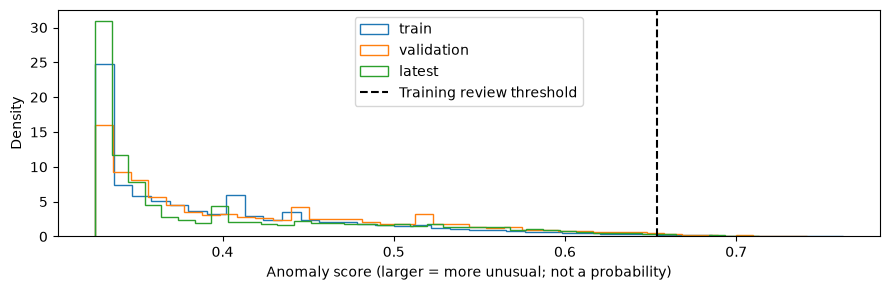

Saved anomaly detector, manifest, scores, summary and review shortlist to: /Users/alfredyap/Documents/GitHub/FYP/data/runs/run_20261019_013241_618240/11_anomalies/2fae5011a2a6495c


In [7]:
summary_rows = []
for name, part in anomaly_scores.groupby("split", sort=False):
    for level, columns in [("overall", []), ("project_group", ["project_group"]),
                           ("state", ["state"]), ("district", ["state", "district"])]:
        groups = [("ALL", part)] if not columns else part.groupby(columns, sort=True)
        for group, rows in groups:
            values = group if isinstance(group, tuple) else (group,)
            summary_rows.append({"split": name, "breakdown": level, "group": " / ".join(map(str, values)),
                **dict(zip(columns, values)), "rows": len(rows), "flagged": int(rows.is_anomaly.sum()),
                "flag_rate_pct": 100 * rows.is_anomaly.mean()})
# Keep an explicitly empty latest population visible in the summary.
if not any(row["split"] == "latest" for row in summary_rows):
    summary_rows.append({"split": "latest", "breakdown": "overall", "group": "ALL", "rows": 0, "flagged": 0, "flag_rate_pct": np.nan})
anomaly_summary = pd.DataFrame(summary_rows)
anomaly_summary.to_csv(OUTPUT_DIR / "anomaly_summary.csv", index=False)
display(anomaly_summary.loc[anomaly_summary.breakdown.eq("overall")])
display(anomaly_summary.loc[anomaly_summary.breakdown.eq("project_group")])
review = pd.concat([part.loc[part.is_anomaly].nlargest(20, "anomaly_score") for part in scored_periods], ignore_index=True)
review.to_csv(OUTPUT_DIR / "review_candidates.csv", index=False)
display(review[["split"] + IDENTIFIERS + ["weekly_median_price"] + list(FEATURE_FORMULAS) + ["anomaly_score"]].head(20))
fig, ax = plt.subplots(figsize=(9, 3))
for name, part in anomaly_scores.groupby("split", sort=False):
    if len(part):
        ax.hist(part.anomaly_score, bins=40, density=True, histtype="step", label=name)
ax.axvline(threshold, color="black", linestyle="--", label="Training review threshold")
ax.set(xlabel="Anomaly score (larger = more unusual; not a probability)", ylabel="Density")
ax.legend(); fig.tight_layout(); plt.show()
print("Saved anomaly detector, manifest, scores, summary and review shortlist to:", OUTPUT_DIR)


## Interpretation

The classifier predicts next-week surges; this detector flags unusual current/past price patterns. They serve different purposes. The detector uses the original supported 2025 training rows, not the classifier's full longer-history population. Its 1% contamination is a training review policy, not a measured error rate or anomaly accuracy. Labels are never features. New data or a different classifier does not justify repeatedly changing this threshold.

No frozen legacy model or dashboard is replaced here. Run 12 for bounded, precomputed classifier explanations and safe dashboard publication.